# Static Planning Agent — Goa Trip + Aviationstack

Sequential workflow:

**User Request → Static Planner → Aviationstack → Flight Recommendation → Day 1 → Day 2 → Day 3 → Final Itinerary**

No parallelization is used.

In [3]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from typing import List, TypedDict
from pydantic import BaseModel
import requests
from langchain_core.messages import SystemMessage,HumanMessage
from langgraph.graph import StateGraph, START, END
from tavily import TavilyClient

In [4]:
load_dotenv()
llm = ChatOpenAI(model="gpt-4o",temperature=0)
AVIATIONSTACK_API_KEY = os.getenv("AVIATIONSTACK_API_KEY")
Tavily_key = os.getenv("TAVILY_API_KEY")
tavily = TavilyClient(api_key=Tavily_key)

## 1. Data models

Pydantic models give the planner a predictable output structure.

In [5]:
class FlightRequirement(BaseModel):
    origin:str
    destination:str
    departure_date:str
    return_date:str
    adults:int

class TripDay(BaseModel):
    day:int
    focus:str
    description:str
    itinerary:str = ""

class TripPlan(BaseModel):
    flight:FlightRequirement
    days: List[TripDay]

class ReportState(TypedDict):
    request:str
    flight_requirement:FlightRequirement
    flight_option: List  ## What are response from aviation stack that details will go here
    recommended_flight:dict  
    days: List[TripDay] ##  this is genereated by process of fan-out
    completed_days: List[TripDay] ## hold the iteneary for all days fan-in
    final_itinerary: str
    

3. Static Planner

The planner creates the high-level plan before execution starts.

In [15]:
Planning_prompt = """ 
You are a travel planning agent.

Create a static travel plan for the user's request.

Return:
1. Flight requirement:
   - origin airport IATA code
   - destination airport IATA code
   - departure date
   - return date
   - number of adults

2. Exactly 3 trip days:
   - day number
   - focus
   - short description


Do not create the detailed itinerary.
Only create the static plan.
"""

In [6]:
def create_trip_plan(state:ReportState):
    structured_llm = llm.with_structured_output(TripPlan)
    response = structured_llm.invoke(
        [
            SystemMessage(content=Planning_prompt),
            HumanMessage(content="Create a static plan for:\n\n" + state["request"])
        ]
    )
    print("=" *60)
    print("STATIC PLAN")
    print("=" *60)
    
    print("\nflight requireemnt")
    print(response.flight)
    
    for day in response.days:
        print(f"Day{day.day}: {day.focus}")
        print(f"Day{day.description}")
    
    return {
        "flight_requirement":response.flight,
        "days":response.days  
    }

In [17]:
# Test the function
test_state = {
    "request": """
    Plan a 3-day trip to Goa for two people.

    We are traveling from Bengaluru.
    Departure date: 2026-10-10
    Return date: 2026-10-12.
    """
}

result = create_trip_plan(test_state)

print("\nRESULT:")
print(result)

STATIC PLAN

flight requireemnt
origin='BLR' destination='GOI' departure_date='2026-10-10' return_date='2026-10-12' adults=2
Day1: Beach Exploration
DaySpend the day exploring the beautiful beaches of Goa, starting with the popular Baga Beach and ending with a sunset at Anjuna Beach.
Day2: Cultural and Historical Sites
DayDiscover the rich cultural heritage of Goa by visiting its famous churches and historical landmarks.
Day3: Nature and Relaxation
DayEnjoy the natural beauty of Goa with a visit to its spice plantations and a relaxing afternoon at a wellness spa.

RESULT:
{'flight_requirement': FlightRequirement(origin='BLR', destination='GOI', departure_date='2026-10-10', return_date='2026-10-12', adults=2), 'days': [TripDay(day=1, focus='Beach Exploration', description='Spend the day exploring the beautiful beaches of Goa, starting with the popular Baga Beach and ending with a sunset at Anjuna Beach.', itinerary='Visit Baga Beach, enjoy water sports, have lunch at a beach shack, rela

## 4. Aviationstack REST API

The Python function calls Aviationstack with an HTTP GET request.

**Python → HTTP → Aviationstack → JSON**

In [7]:
def search_flight(requirement: FlightRequirement, flight_opt):
    if not AVIATIONSTACK_API_KEY:
        raise ValueError("AVIATIONSTACK_API_KEY is not configured")

    url = "https://api.aviationstack.com/v1/flights"

    if flight_opt == "dep":
        dep_iata = requirement.origin
        arr_iata = requirement.destination
    elif flight_opt == "arr":
        dep_iata = requirement.destination
        arr_iata = requirement.origin
    else:
        raise ValueError("flight_opt must be either 'dep' or 'arr'")

    querystring = {
        "access_key": AVIATIONSTACK_API_KEY,
        "dep_iata": dep_iata,
        "arr_iata": arr_iata,
        "limit": 10
    }

    headers = {
        "Accept": "application/json"
    }

    response = requests.get(
        url,
        headers=headers,
        params=querystring,
        timeout=30
    )

    response.raise_for_status()

    data = response.json()

    if "error" in data:
        raise RuntimeError(
            "Aviationstack error: " + str(data["error"])
        )

    return data.get("data", [])

In [27]:
# Lets test the function:
requirement = FlightRequirement(
    origin="BLR",
    destination="GOI",
    departure_date="2026-10-10",
    return_date="2026-10-12",
    adults=2
)
flight = search_flight(requirement,"arr")
print(flight)

[{'flight_date': '2026-09-21', 'flight_status': 'active', 'departure': {'airport': 'Goa International', 'timezone': 'Asia/Kolkata', 'iata': 'GOI', 'icao': 'VOGO', 'terminal': None, 'gate': None, 'delay': None, 'scheduled': '2026-09-21T22:50:00+00:00', 'estimated': '2026-09-21T22:50:00+00:00', 'actual': None, 'estimated_runway': None, 'actual_runway': None}, 'arrival': {'airport': 'Bangalore International Airport', 'timezone': 'Asia/Kolkata', 'iata': 'BLR', 'icao': 'VOBL', 'terminal': '1', 'gate': None, 'baggage': '8A', 'scheduled': '2026-09-22T00:25:00+00:00', 'delay': None, 'estimated': None, 'actual': None, 'estimated_runway': None, 'actual_runway': None}, 'airline': {'name': 'Alliance Air', 'iata': '9I', 'icao': 'LLR'}, 'flight': {'number': '548', 'iata': '9I548', 'icao': 'LLR548', 'codeshared': None}, 'aircraft': None, 'live': None}, {'flight_date': '2026-09-21', 'flight_status': 'active', 'departure': {'airport': 'Goa International', 'timezone': 'Asia/Kolkata', 'iata': 'GOI', 'ica

## 5. Transform Aviationstack response

The raw API response is converted into a smaller structure that is easier for the LLM to interpret.

In [8]:
def format_flight_option(fligths):
    options = []
    for index,flight in enumerate(fligths):
        
        departure = flight.get("departure", {})
        arrival = flight.get("arrival", {})
        airline = flight.get("airline", {})
        flight_info = flight.get("flight", {})

        options.append({
            "option": index,
            "flight_number": flight_info.get("iata"),
            "airline": airline.get("name"),
            "departure_iata": departure.get("iata"),
            "scheduled_departure": departure.get("scheduled"),
            "arrival_iata": arrival.get("iata"),
            "scheduled_arrival": arrival.get("scheduled"),
            "status": flight.get("flight_status")
        })

    return options
        
        

## 6. Flight recommendation

The LLM reasons over the returned flight information. It does not claim booking confirmation.

In [28]:
FLIGHT_RECOMMENDATION_PROMPT = """
You are a travel assistant.

Review the flight information returned by the aviation data API.

Recommend the most convenient option for both way based on:
- departure time
- arrival time
- flight status
- convenience


Do not invent prices, availability, or booking information.

State that the result is a recommendation, not a booking confirmation.
"""

def process_flight(state:ReportState):
    requirement = state['flight_requirement']
    
    print("=" *60)
    print("AViATION STACK SEARCH")
    print("=" *60)
    dep_flights = search_flight(requirement,"dep")
    arr_flight =  search_flight(requirement,"arr")
    option_dep = format_flight_option(dep_flights)
    option_arr = format_flight_option(arr_flight)
    options =  option_dep + option_arr
    
    print("\nFound " + str(len(options)) + " flight records.")
    if not options:
        recommendation = {"recommendation":"No Flight records were found"}
    else:
        prompt = (
            "Trip requirement\n:"
            + requirement.model_dump_json(indent=2)
            + "\n\nFlight information:\n"
            + str(options)
            + "\n\nRecommend the most convenient option for two way"
        )
        response = llm.invoke([
            SystemMessage(content=FLIGHT_RECOMMENDATION_PROMPT),
            HumanMessage(content=prompt)
        ])
        recommendation = {"recommendation":response.content}
    print("\n" + recommendation["recommendation"])
    
    return {
        "flight_option":options,
        "recommended_flight":recommendation
    }
    

In [29]:
# LEts test the functio
test_state = {
    "flight_requirement": FlightRequirement(
        origin="BLR",
        destination="GOI",
        departure_date="2026-10-10",
        return_date="2026-10-12",
        adults=2
    )
}

result = process_flight(test_state)

print(result)

AViATION STACK SEARCH

Found 20 flight records.

Based on the flight information provided, here is a recommendation for the most convenient options for your round trip from Bangalore (BLR) to Goa (GOI) and back:

### Outbound Flight (BLR to GOI):
- **Flight Number**: IX1538
- **Airline**: Air India Express
- **Scheduled Departure**: 2026-09-21 at 17:15 (UTC)
- **Scheduled Arrival**: 2026-09-21 at 18:30 (UTC)
- **Status**: Landed

**Reason for Recommendation**: This flight departs earlier in the evening, allowing you to arrive in Goa by 18:30, giving you more time to settle in and enjoy your evening.

### Return Flight (GOI to BLR):
- **Flight Number**: 6E6163
- **Airline**: IndiGo
- **Scheduled Departure**: 2026-09-21 at 19:25 (UTC)
- **Scheduled Arrival**: 2026-09-21 at 20:55 (UTC)
- **Status**: Active

**Reason for Recommendation**: This return flight departs at a convenient time in the evening, allowing you to enjoy most of your day in Goa before heading back to Bangalore.

Please n

## 7. Generate research queries for each day

The LLM creates queries that Tavily will use for web research.

In [9]:
def generate_day_queries(day:TripDay):
    response = llm.invoke([
        SystemMessage(
            content=(
                "you are travel reasearch assistant."
                "Generate 3 useful web-search queries for this Goa trip day."
                "Return only the queries"
            )    
        ),
        HumanMessage(
            content=(
                f"Day: {day.day}\n"
                f"Focus:{day.focus}\n"
                f"Description: {day.description}\n\n"
                "Generate 3 useful reasearch queries"
            )
        )
    ])
    return response.content

In [42]:
# Lets test the function
test_day = TripDay(
    day=1,
    focus="North Goa beaches",
    description="Explore popular beaches, local attractions, and nearby places in North Goa."
)

queries = generate_day_queries(test_day)

print("Generated queries:")
print(queries)

Generated queries:
1. "Top beaches to visit in North Goa and nearby attractions"
2. "Local attractions and activities near North Goa beaches"
3. "Best beachside restaurants and cafes in North Goa"


## 8. Tavily research

In [10]:
def research_day(day:TripDay,queries:str):
    if not Tavily_key:
        ValueError("Tavily API Key is not configured")
        
    return tavily.search(
        query=queries,
        search_depth='advanced',
        max_results=5
    )

In [11]:
queries = """Top beaches to visit in North Goa and nearby attractions
Local attractions and activities near North Goa beaches
Best beachside restaurants and cafes in North Goa
"""
result = research_day(None,queries)
print(result)

{'query': 'Top beaches to visit in North Goa and nearby attractions\nLocal attractions and activities near North Goa beaches\nBest beachside restaurants and cafes in North Goa', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://weekendtourguide.com/best-beaches-in-north-goa', 'title': 'Explore the Top Beaches in North Goa | नॉर्थ गोवा Travel Guide 2025 - Weekend Tour Guide', 'content': 'Title: Explore the Top Beaches in North Goa | नॉर्थ गोवा Travel Guide 2025 - Weekend Tour Guide\n# Explore the Top Beaches in North Goa | नॉर्थ गोवा Travel Guide 2025. * Best Beaches in North Goa. Vagator Beach | Best Beaches in North Goa. Ashwem Beach | Best Beaches in North Goa. Miramar Beach | Best Beaches in North Goa. Kegdole Beach | Best Beaches in North Goa. Vagator Beach | Best Beaches in North Goa**. Ashwem Beach | Best Beaches in North Goa**. Miramar Beach | Best Beaches in North Goa**. Kegdole Beach | Best Beaches in North Goa**. ## Best Beaches in North 

## 9. Write one day's itinerary

In [47]:
def write_day(day: TripDay, research):
    
    response = llm.invoke([
        SystemMessage(
            content=(
                "You are an expert travel itinerary writer. "
                "Create a practical itinerary for two people. "
                "Use the supplied research. "
                "Do not invent unsupported facts."
            )
        ),
        HumanMessage(
            content=(
                f"Day: {day.day}\n"
                f"Focus: {day.focus}\n"
                f"Description: {day.description}\n\n"
                f"Research:\n{research}\n\n"
                "Create the detailed itinerary for this day."
            )
        )
    ])

    day.itinerary = response.content
    return day


In [48]:
# Test the function
test_day = TripDay(
    day=1,
    focus="North Goa beaches",
    description="Explore popular beaches and attractions in North Goa."
)

research = """
Baga Beach is a popular beach in North Goa.
Calangute Beach is another well-known beach in the area.
Fort Aguada is a historic fort and tourist attraction.
Candolim is known for its beach and nearby restaurants.
"""
result = write_day(test_day, research)

print(result.itinerary)

**Day 1: Exploring North Goa Beaches**

**Morning:**

- **8:00 AM - Breakfast at Candolim:**
  Start your day with a hearty breakfast at one of the charming cafes in Candolim. Consider visiting "Cafe Chocolatti" for a delightful mix of continental breakfast options and freshly brewed coffee.

- **9:30 AM - Visit Fort Aguada:**
  Head to Fort Aguada, a 17th-century Portuguese fort offering panoramic views of the Arabian Sea. Spend about an hour exploring the fort and its lighthouse, capturing some stunning photographs.

**Late Morning:**

- **11:00 AM - Relax at Candolim Beach:**
  Make your way to Candolim Beach, known for its serene environment and less crowded shores. Enjoy a leisurely stroll along the beach or relax under a beach umbrella with a refreshing coconut water.

**Afternoon:**

- **12:30 PM - Lunch at Calangute:**
  Travel to Calangute Beach and have lunch at one of the beachside shacks. "Pousada by the Beach" offers a great selection of Goan and seafood dishes with a view

## 10. Sequential day processing

A normal Python `for` loop deliberately processes:

**Day 1 → Day 2 → Day 3**

No parallel execution is used.

In [49]:
def process_days_sequentially(state: ReportState):
    
    completed_days = []
    print(state["days"])
    for day in state["days"]:

        print("\n" + "=" * 60)
        print(f"PROCESSING DAY {day.day}: {day.focus}")
        print("=" * 60)

        queries = generate_day_queries(day)
        research = research_day(day, queries)
        completed_day = write_day(day, research)

        completed_days.append(completed_day)

        print(f"Day {day.day} completed.")

    return {
        "completed_days": completed_days
    }

## 11. Combine the results

In [50]:
def combine_trip(state: ReportState):
    
    parts = [
        "# Flight Recommendation\n\n"
        + state["recommended_flight"]["recommendation"]
    ]

    for day in state["completed_days"]:
        parts.append(
            f"# Day {day.day}: {day.focus}\n\n"
            f"{day.itinerary}"
        )

    return {
        "final_itinerary": "\n\n".join(parts)
    }

## 12. Build the sequential LangGraph

The edges define the execution order.

In [51]:
graph_builder = StateGraph(ReportState)

graph_builder.add_node("create_trip_plan", create_trip_plan)
graph_builder.add_node("process_flights", process_flight)
graph_builder.add_node("process_days_sequentially", process_days_sequentially)
graph_builder.add_node("combine_trip", combine_trip)

graph_builder.add_edge(START, "create_trip_plan")
graph_builder.add_edge("create_trip_plan", "process_flights")
graph_builder.add_edge("process_flights", "process_days_sequentially")
graph_builder.add_edge("process_days_sequentially", "combine_trip")
graph_builder.add_edge("combine_trip", END)

trip_graph = graph_builder.compile()

print("Graph compiled successfully.")


Graph compiled successfully.


## 13. Visualize the graph

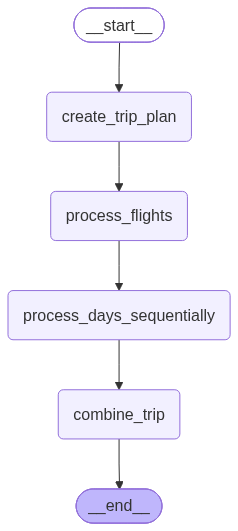

In [52]:
from IPython.display import Image, display

try:
    display(Image(trip_graph.get_graph().draw_mermaid_png()))
except Exception:
    print(trip_graph.get_graph().draw_mermaid())

## 14. API configuration

Create a `.env` file beside the notebook:

```text
OPENAI_API_KEY=your_openai_key
AVIATIONSTACK_API_KEY=your_aviationstack_key
TAVILY_API_KEY=your_tavily_key
```

Do not hard-code API keys.

## 15. Run the agent

Change the dates to the dates you want to demonstrate.

In [53]:
request = """
Plan a 3-day trip to Goa for two people.

We are traveling from Bengaluru.

Departure date: 2026-10-10
Return date: 2026-10-12.

Use Aviationstack to retrieve flight information.
Use Tavily for Goa travel research.

Process the trip sequentially.
"""

result = trip_graph.invoke({
    "request": request,
    "flight_requirement": {},
    "flight_options": [],
    "recommended_flight": {},
    "days": [],
    "completed_days": [],
    "final_itinerary": ""
})

STATIC PLAN

flight requireemnt
origin='BLR' destination='GOI' departure_date='2026-10-10' return_date='2026-10-12' adults=2
Day1: Beach Exploration
DaySpend the day exploring the beautiful beaches of Goa, starting with the popular Baga Beach and then heading to the serene Anjuna Beach for a relaxing afternoon.
Day2: Cultural and Historical Sites
DayDiscover the rich cultural heritage of Goa by visiting its famous churches and historical landmarks.
Day3: Nature and Adventure
DayExperience the natural beauty and adventure activities in Goa by visiting the Dudhsagar Waterfalls and spice plantations.
AViATION STACK SEARCH

Found 20 flight records.

Based on the flight information provided, here is a recommendation for the most convenient options for your round trip from Bangalore (BLR) to Goa (GOI) and back:

### Outbound Flight (BLR to GOI):
- **Flight Number**: 6E194
- **Airline**: IndiGo
- **Scheduled Departure**: 2026-09-22 at 06:05 AM
- **Scheduled Arrival**: 2026-09-22 at 07:20 AM
-

In [54]:
print("=" * 80)
print("FINAL GOA TRIP PLAN")
print("=" * 80)
print(result["final_itinerary"])

FINAL GOA TRIP PLAN
# Flight Recommendation

Based on the flight information provided, here is a recommendation for the most convenient options for your round trip from Bangalore (BLR) to Goa (GOI) and back:

### Outbound Flight (BLR to GOI):
- **Flight Number**: 6E194
- **Airline**: IndiGo
- **Scheduled Departure**: 2026-09-22 at 06:05 AM
- **Scheduled Arrival**: 2026-09-22 at 07:20 AM
- **Status**: Scheduled

This flight is recommended because it departs early in the morning, allowing you to make the most of your day in Goa. Additionally, IndiGo is known for its punctuality and service.

### Return Flight (GOI to BLR):
- **Flight Number**: 6E6557
- **Airline**: IndiGo
- **Scheduled Departure**: 2026-09-21 at 08:55 PM
- **Scheduled Arrival**: 2026-09-21 at 10:15 PM
- **Status**: Active

This return flight is recommended as it departs in the evening, giving you a full day in Goa before heading back to Bangalore. The flight status is active, indicating it is currently operating as plann